# Clawsify

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
import timm


import matplotlib.pyplot as plt # For data viz
import pandas as pd
import numpy as np
import sys
from tqdm.notebook import tqdm

In [4]:
print('System Version:', sys.version)
print('PyTorch version', torch.__version__)
print('Torchvision version', torchvision.__version__)
print('Numpy version', np.__version__)
print('Pandas version', pd.__version__)

System Version: 3.11.17 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:16:54) [MSC v.1942 64 bit (AMD64)]
PyTorch version 2.5.1+cu121
Torchvision version 0.20.1+cu121
Numpy version 2.4.6
Pandas version 3.0.6


### Dataset

In [8]:
class BigCatsDataset(Dataset):
    def __init__(self, data_dir, transform=None):
        self.data = ImageFolder(data_dir, transform=transform)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

    @property
    def classes(self):
        return self.data.classes

In [9]:
dataset = BigCatsDataset(data_dir=r'archive\train')

In [10]:
len(dataset)

2339

In [15]:
dataset[455]

(<PIL.Image.Image image mode=RGB size=224x224>, 1)

0


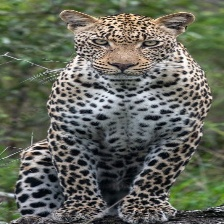

In [22]:
image, lable = dataset[100]
print(lable)
image

In [23]:
data_dir = r'archive\train'
target_to_class = {v: k for k, v in ImageFolder(data_dir).class_to_idx.items()}
print(target_to_class)

{0: 'AFRICAN LEOPARD', 1: 'CARACAL', 2: 'CHEETAH', 3: 'CLOUDED LEOPARD', 4: 'JAGUAR', 5: 'LIONS', 6: 'OCELOT', 7: 'PUMA', 8: 'SNOW LEOPARD', 9: 'TIGER'}


In [25]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

data_dir = r'archive\train'
dataset = BigCatsDataset(data_dir, transform)

In [27]:
dataset[5]

(tensor([[[0.4039, 0.4235, 0.4784,  ..., 0.3961, 0.3961, 0.4000],
          [0.3373, 0.4235, 0.4863,  ..., 0.3765, 0.3686, 0.3686],
          [0.2863, 0.4353, 0.4941,  ..., 0.3529, 0.3255, 0.3255],
          ...,
          [0.1490, 0.2157, 0.2471,  ..., 0.5804, 0.6902, 0.6471],
          [0.1216, 0.1843, 0.2078,  ..., 0.6157, 0.6745, 0.5686],
          [0.1098, 0.2235, 0.1961,  ..., 0.4824, 0.4980, 0.4627]],
 
         [[0.5098, 0.5176, 0.5373,  ..., 0.4941, 0.4941, 0.4706],
          [0.4431, 0.5216, 0.5529,  ..., 0.4784, 0.4784, 0.4588],
          [0.3922, 0.5294, 0.5686,  ..., 0.4549, 0.4471, 0.4392],
          ...,
          [0.1765, 0.2824, 0.3490,  ..., 0.6510, 0.6784, 0.6157],
          [0.1647, 0.2706, 0.2824,  ..., 0.6118, 0.6353, 0.5412],
          [0.1412, 0.2824, 0.2275,  ..., 0.4706, 0.4745, 0.4471]],
 
         [[0.4431, 0.4392, 0.4667,  ..., 0.4863, 0.4784, 0.4588],
          [0.3647, 0.4353, 0.4784,  ..., 0.4745, 0.4627, 0.4471],
          [0.2980, 0.4314, 0.4863,  ...,

In [28]:
image, lable = dataset[100]
image.shape

torch.Size([3, 128, 128])

### Dataloaders

In [29]:
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

In [35]:
for images, labels in dataloader:
    break

In [36]:
images.shape, labels.shape

(torch.Size([32, 3, 128, 128]), torch.Size([32]))

In [37]:
labels

tensor([3, 4, 9, 7, 8, 3, 7, 6, 3, 2, 3, 4, 9, 8, 1, 1, 5, 1, 5, 0, 6, 8, 8, 8,
        3, 5, 7, 8, 7, 5, 5, 6])

### Model

In [38]:
class BigCatsClassifier(nn.Module):
    def __init__(self, num_classes=10):
        # Define all parts of the model
        super(BigCatsClassifier, self).__init__()
        self.base_model = timm.create_model('efficientnet_b0', pretrained=True)
        self.features = nn.Sequential(*list(self.base_model.children())[:-1])

        enet_out_size = 1280
        # Make a classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(enet_out_size, num_classes)
        )
    
    def forward(self, x):
        # Connect these parts and return the output
        x = self.features(x)
        output = self.classifier(x)
        return output

In [39]:
model = BigCatsClassifier(num_classes=10)

c:\USERS\NAJLA\ANACONDA3\ENVS\BELAJARPYTORCH\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\najla\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

c:\USERS\NAJLA\ANACONDA3\ENVS\BELAJARPYTORCH\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\najla\.cache\huggingface\hub\models--timm--efficientnet_b0.ra_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [40]:
print(model)

BigCatsClassifier(
  (base_model): EfficientNet(
    (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (bn1): BatchNormAct2d(
            32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          )
          (con

In [44]:
example_out = model(images)
example_out.shape

torch.Size([32, 10])

### Traning Loop

In [45]:
# Loss function
criterion = nn.CrossEntropyLoss()
# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [49]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

train_folder = r'archive\train'
valid_folder = r'archive\valid'
test_folder = r'archive\test'

train_dataset = BigCatsDataset(train_folder, transform=transform)
val_dataset = BigCatsDataset(valid_folder, transform=transform)
test_dataset = BigCatsDataset(test_folder, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [ ]:
num_epochs = 5
train_losses, val_losses = [], []

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

model = BigCatsClassifier(num_classes=10)
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(num_epochs):
    # Training phase
    model.train()
    running_loss = 0.0
    for images, labels in tqdm(train_loader, desc='Training loop'):
        # Move inputs and labels to the device
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
    train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(train_loss)
    
    # Validation phase
    model.eval()
    running_loss = 0.0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc='Validation loop'):
            # Move inputs and labels to the device
            images, labels = images.to(device), labels.to(device)
         
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * labels.size(0)
    val_loss = running_loss / len(val_loader.dataset)
    val_losses.append(val_loss)
    print(f"Epoch {epoch+1}/{num_epochs} - Train loss: {train_loss}, Validation loss: {val_loss}")